# Imputation, Decision Trees & Ensemble Learning

Hands-on practice with three ideas in scikit-learn:

1. **Imputing missing values in high-dimensional data**: median imputation (fit on the training split only) before L1-regularised logistic regression on a gene-expression dataset (~21k features, 172 samples).
2. **Decision trees**: how `max_depth` controls under- and overfitting, plus reading a fitted tree to follow a single prediction by hand.
3. **Ensembles of trees**: bagging, pasting, random forests and AdaBoost compared across tree sizes (`min_samples_leaf`).

The same habits apply throughout: fixed random seeds for reproducibility, a held-out test set, and preprocessing fitted on training data only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier

## 1. Imputing Missing Values: Sparse Logistic Regression on Gene Expression

**172 samples and ~21,000 gene-expression features** with a binary label `ClassType`. A few samples have missing values. Dropping those rows throws away scarce samples, so this time the gaps are **imputed with the per-gene median**.

To avoid **data leakage**, the imputer and the scaler are fitted on the training split only and then applied to the test split. With p ≫ n, **L1 regularisation** pushes most coefficients to exactly zero, so the model selects a small set of genes.

> The dataset is included at `data/GenomicData.csv` (see `data/README.md`).

In [2]:
df = pd.read_csv('../data/GenomicData.csv')
print('original shape:', df.shape)

df = df.iloc[:, 2:]   # index + sample-ID columns carry no signal
print('after dropping ID columns:', df.shape)
print('missing values:', int(df.isna().sum().sum()))

np.random.seed(42)

y = df['ClassType']
X = df.drop(columns=['ClassType'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print('train:', X_train.shape, '| test:', X_test.shape)

imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)   # medians learned from training data only
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_imp)
X_test_s = scaler.transform(X_test_imp)

original shape: (172, 21053)
after dropping ID columns: (172, 21051)


missing values: 1988


train: (129, 21050) | test: (43, 21050)


In [3]:
for C in [0.05, 10]:
    model = LogisticRegression(l1_ratio=1, solver='liblinear', C=C).fit(X_train_s, y_train)  # l1_ratio=1 -> pure L1
    acc = model.score(X_test_s, y_test)
    n_selected = int(np.sum(model.coef_ != 0))
    print(f'C={C:<5} test accuracy = {acc:.4f} | genes selected = {n_selected} / {X_train_s.shape[1]}')

C=0.05  test accuracy = 0.9070 | genes selected = 10 / 21050
C=10    test accuracy = 1.0000 | genes selected = 220 / 21050


**Takeaways**
- Median imputation keeps **every sample**, which matters when there are only 172 of them.
- With strong regularisation (**C = 0.05**) only a handful of genes get non-zero weights, giving a compact, interpretable model.
- With weak regularisation (**C = 10**) many more genes are kept and test accuracy goes up. This is the trade-off between sparsity and accuracy.
- The imputer is a learned transformer, just like the scaler. Fitting it on the full dataset would leak test-set statistics into training.

## 2. Decision Trees: Depth and Interpretation

The Iris dataset (150 flowers, 4 measurements, 3 species). Four trees are trained with `max_depth` from 1 to 4 to see how depth affects test accuracy.

In [4]:
iris = datasets.load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

trees, accuracies = {}, {}
for depth in [1, 2, 3, 4]:
    tree = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42).fit(X_train, y_train)
    trees[depth] = tree
    accuracies[depth] = tree.score(X_test, y_test)
    print(f'max_depth={depth}: test accuracy = {accuracies[depth]:.4f}')

best_depth = max(accuracies, key=accuracies.get)
best_tree = trees[best_depth]
print(f'\nbest max_depth = {best_depth} (accuracy = {accuracies[best_depth]:.4f})')

max_depth=1: test accuracy = 0.6667
max_depth=2: test accuracy = 0.9333
max_depth=3: test accuracy = 0.9667
max_depth=4: test accuracy = 0.9333

best max_depth = 3 (accuracy = 0.9667)


### Visualising the best tree

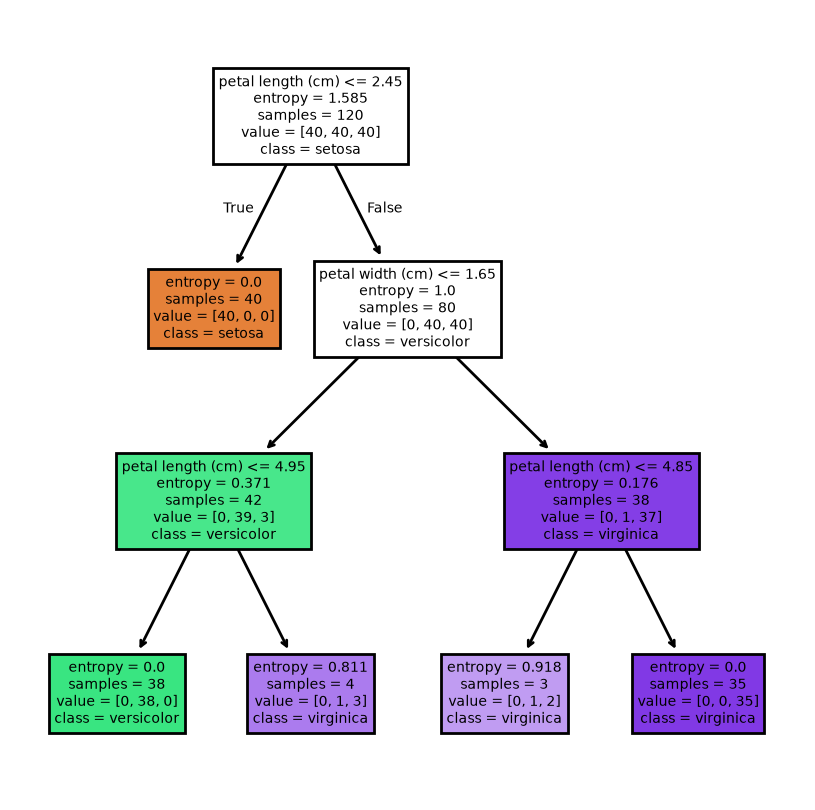

In [5]:
plt.figure(figsize=(5, 5), dpi=200)
plot_tree(best_tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

### Following one prediction by hand

A new flower with sepal length 5.2 cm, sepal width 2.6 cm, petal length 3.9 cm and petal width 1.4 cm.

In [6]:
new_flower = [[5.2, 2.6, 3.9, 1.4]]
print('predicted species:', iris.target_names[best_tree.predict(new_flower)[0]])

predicted species: versicolor


**Takeaways**
- A depth-1 tree (a single split) can only separate one species from the other two, so it underfits.
- Accuracy peaks at depth 3. At depth 4 the extra splits fit the training data more closely, and test accuracy drops slightly, which is a small sign of overfitting.
- Tracing the path in the plot gives the same answer as `predict`:
  1. petal length 3.9 > 2.45, so the flower is not *setosa*
  2. petal width 1.4 ≤ 1.65, so it goes to the left branch
  3. petal length 3.9 ≤ 4.95, so it lands in the **versicolor** leaf

  This step-by-step readability is the main strength of decision trees.

## 3. Ensemble Learning: Bagging, Pasting, Random Forest and AdaBoost

To make the problem harder, only the **first two Iris features** (sepal length and sepal width) are used. Each ensemble uses 50 CART trees, and the tree size is controlled with `min_samples_leaf`:
- **small** `min_samples_leaf` → **deep** trees (low bias, high variance)
- **large** `min_samples_leaf` → **shallow** trees (higher bias, lower variance)

| Method | How the trees differ |
|---|---|
| Bagging | Bootstrap samples (with replacement) |
| Pasting | Random subsets without replacement |
| Random forest | Bootstrap samples + random feature subset at each split |
| AdaBoost | Trees trained in sequence, each focusing on earlier mistakes |

In [7]:
X = iris.data[:, [0, 1]]
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100, stratify=y)

leaf_values = [2, 5, 10, 20]
results = {'Bagging': {}, 'Pasting': {}, 'Random Forest': {}, 'AdaBoost': {}}

for leaf in leaf_values:
    cart = DecisionTreeClassifier(min_samples_leaf=leaf, criterion='gini')
    models = {
        'Bagging': BaggingClassifier(estimator=cart, n_estimators=50, random_state=42),
        'Pasting': BaggingClassifier(estimator=cart, n_estimators=50, bootstrap=False, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=50, min_samples_leaf=leaf, criterion='gini',
                                                max_features='sqrt', random_state=42),
        'AdaBoost': AdaBoostClassifier(estimator=cart, n_estimators=50, random_state=42),
    }
    for name, model in models.items():
        results[name][leaf] = model.fit(X_train, y_train).score(X_test, y_test)

table = pd.DataFrame(results)
table.index.name = 'min_samples_leaf'
table.round(3)

,Bagging,Pasting,Random Forest,AdaBoost
min_samples_leaf,,,,
2,0.733,0.667,0.8,0.733
5,0.633,0.667,0.8,0.667
10,0.633,0.567,0.7,0.733
20,0.633,0.633,0.7,0.733


In [8]:
for name in results:
    scores = results[name]
    best_leaf = max(leaf_values, key=lambda leaf: scores[leaf])   # first (deepest) leaf size wins ties
    kind = 'deep' if best_leaf <= 5 else 'shallow'
    print(f'{name:<14} best accuracy = {scores[best_leaf]:.3f} at min_samples_leaf = {best_leaf:<2} -> {kind} trees')

Bagging        best accuracy = 0.733 at min_samples_leaf = 2  -> deep trees
Pasting        best accuracy = 0.667 at min_samples_leaf = 2  -> deep trees
Random Forest  best accuracy = 0.800 at min_samples_leaf = 2  -> deep trees
AdaBoost       best accuracy = 0.733 at min_samples_leaf = 2  -> deep trees


**Takeaways**
- **Bagging, pasting and random forests do best with deep trees.** Averaging many low-bias, high-variance trees cancels out much of their variance, so the individual trees can afford to overfit.
- **Random forest** scores highest overall. Random feature selection at each split decorrelates the trees, which makes averaging more effective.
- **AdaBoost** works the other way round: it reduces bias by adding weak learners in sequence, so it does not depend on deep trees. Here its accuracy is about the same for deep and shallow trees.
- With only two features and 30 test samples, differences of one or two predictions move accuracy by 3 to 7 points, so these numbers are noisy.

## Summary of skills practised

- **Missing-data imputation** with `SimpleImputer`, fitted on training data only to avoid leakage
- **Sparse (L1) logistic regression** for feature selection when p ≫ n
- **Decision trees**: tuning `max_depth`, spotting under- and overfitting, and reading the fitted tree with `plot_tree`
- **Bagging vs pasting**: sampling with and without replacement
- **Random forests**: adding random feature subsets to decorrelate trees
- **Boosting (AdaBoost)**: sequential learners that reduce bias
- How tree size (`min_samples_leaf`) interacts with each ensemble method